# GAN Augmentation Phase 2: Refined & Calibrated Evaluation

This report compares the Phase 1 results against the Phase 2 improvements (Statistical Filtering, Sample Weighting, and Probability Calibration).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from xgboost import XGBClassifier
from tensorflow.keras.models import load_model

# 1. Load Data
real_df = pd.read_csv('../ml_training/dataset/unsw_nb_cleaned.csv')
features = ['proto', 'state', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'ct_srv_src', 'ct_dst_ltm']

# Recreate test set (same split as previous)
X_real = real_df[features].copy()
y_real = real_df['attack_cat'].copy()
X_train, X_test, y_train, y_test = train_test_split(X_real, y_real, test_size=0.15, random_state=42, stratify=y_real)

# Preprocess
le_dict = {}
for c in ['proto', 'state']:
    le = LabelEncoder()
    le.fit(X_train[c].astype(str))
    X_test.loc[:, c] = X_test[c].map(lambda s: le.transform([s])[0] if s in le.classes_ else -1)

scaler = joblib.load('../ml_training/artifacts_improved/scaler.pkl')
label_encoder = joblib.load('../ml_training/artifacts_improved/label_encoder.pkl')
X_test_scaled = scaler.transform(X_test)
y_test_enc = label_encoder.transform(y_test)
classes = label_encoder.classes_

# 2. Load All Models
print("Loading models...")
# XGBoost Versions
xgb_orig = XGBClassifier()
xgb_orig.load_model('finetune/xgboost_original.json')

xgb_v1 = XGBClassifier()
xgb_v1.load_model('finetune/xgboost_finetuned.model')

xgb_v2 = joblib.load('finetune_v2/xgboost_finetuned_v2.pkl')

# CNN-LSTM Versions
cnn_v1 = load_model('finetune/cnn_lstm_finetuned.keras')
cnn_v2 = load_model('finetune_v2/cnn_lstm_finetuned_v2.keras')

# 3. Evaluation Function
def evaluate(model, X, y, name, is_keras=False):
    if is_keras:
        X_seq = np.expand_dims(X, axis=1)
        y_pred = np.argmax(model.predict(X_seq, verbose=0), axis=1)
    else:
        y_pred = model.predict(X)
    
    acc = accuracy_score(y, y_pred)
    f1 = f1_score(y, y_pred, average='macro')
    return y_pred, acc, f1

# Run Predictions
y_p_xgb0, acc0, f10 = evaluate(xgb_orig, X_test_scaled, y_test_enc, "XGB Original")
y_p_xgb1, acc1, f11 = evaluate(xgb_v1, X_test_scaled, y_test_enc, "XGB Phase 1")
y_p_xgb2, acc2, f12 = evaluate(xgb_v2, X_test_scaled, y_test_enc, "XGB Phase 2")
y_p_cnn1, acc_c1, f1_c1 = evaluate(cnn_v1, X_test_scaled, y_test_enc, "CNN Phase 1", True)
y_p_cnn2, acc_c2, f1_c2 = evaluate(cnn_v2, X_test_scaled, y_test_enc, "CNN Phase 2", True)

# Display Summary Table
summary = pd.DataFrame({
    'Model': ['XGB Original', 'XGB Phase 1', 'XGB Phase 2', 'CNN Phase 1', 'CNN Phase 2'],
    'Accuracy': [acc0, acc1, acc2, acc_c1, acc_c2],
    'Macro F1': [f10, f11, f12, f1_c1, f1_c2]
})
print("\nComparison Summary:")
print(summary)

print("\nPhase 2 Detailed Report (XGBoost):")
print(classification_report(y_test_enc, y_p_xgb2, target_names=classes))


Loading models...

Comparison Summary:
          Model  Accuracy  Macro F1
0  XGB Original  0.738841  0.525990
1   XGB Phase 1  0.781538  0.574547
2   XGB Phase 2  0.802677  0.599899
3   CNN Phase 1  0.713178  0.396071
4   CNN Phase 2  0.729678  0.355989

Phase 2 Detailed Report (XGBoost):
                precision    recall  f1-score   support

      Analysis       0.34      0.18      0.24       300
      Backdoor       0.70      0.12      0.21       262
           DoS       0.34      0.59      0.43      1840
      Exploits       0.71      0.67      0.69      5009
       Fuzzers       0.70      0.74      0.72      2728
       Generic       1.00      0.98      0.99      6000
        Normal       0.95      0.88      0.92      8400
Reconnaissance       0.90      0.74      0.81      1574
     Shellcode       0.41      0.70      0.52       170
         Worms       0.34      0.84      0.48        19

      accuracy                           0.80     26302
     macro avg       0.64      0.64

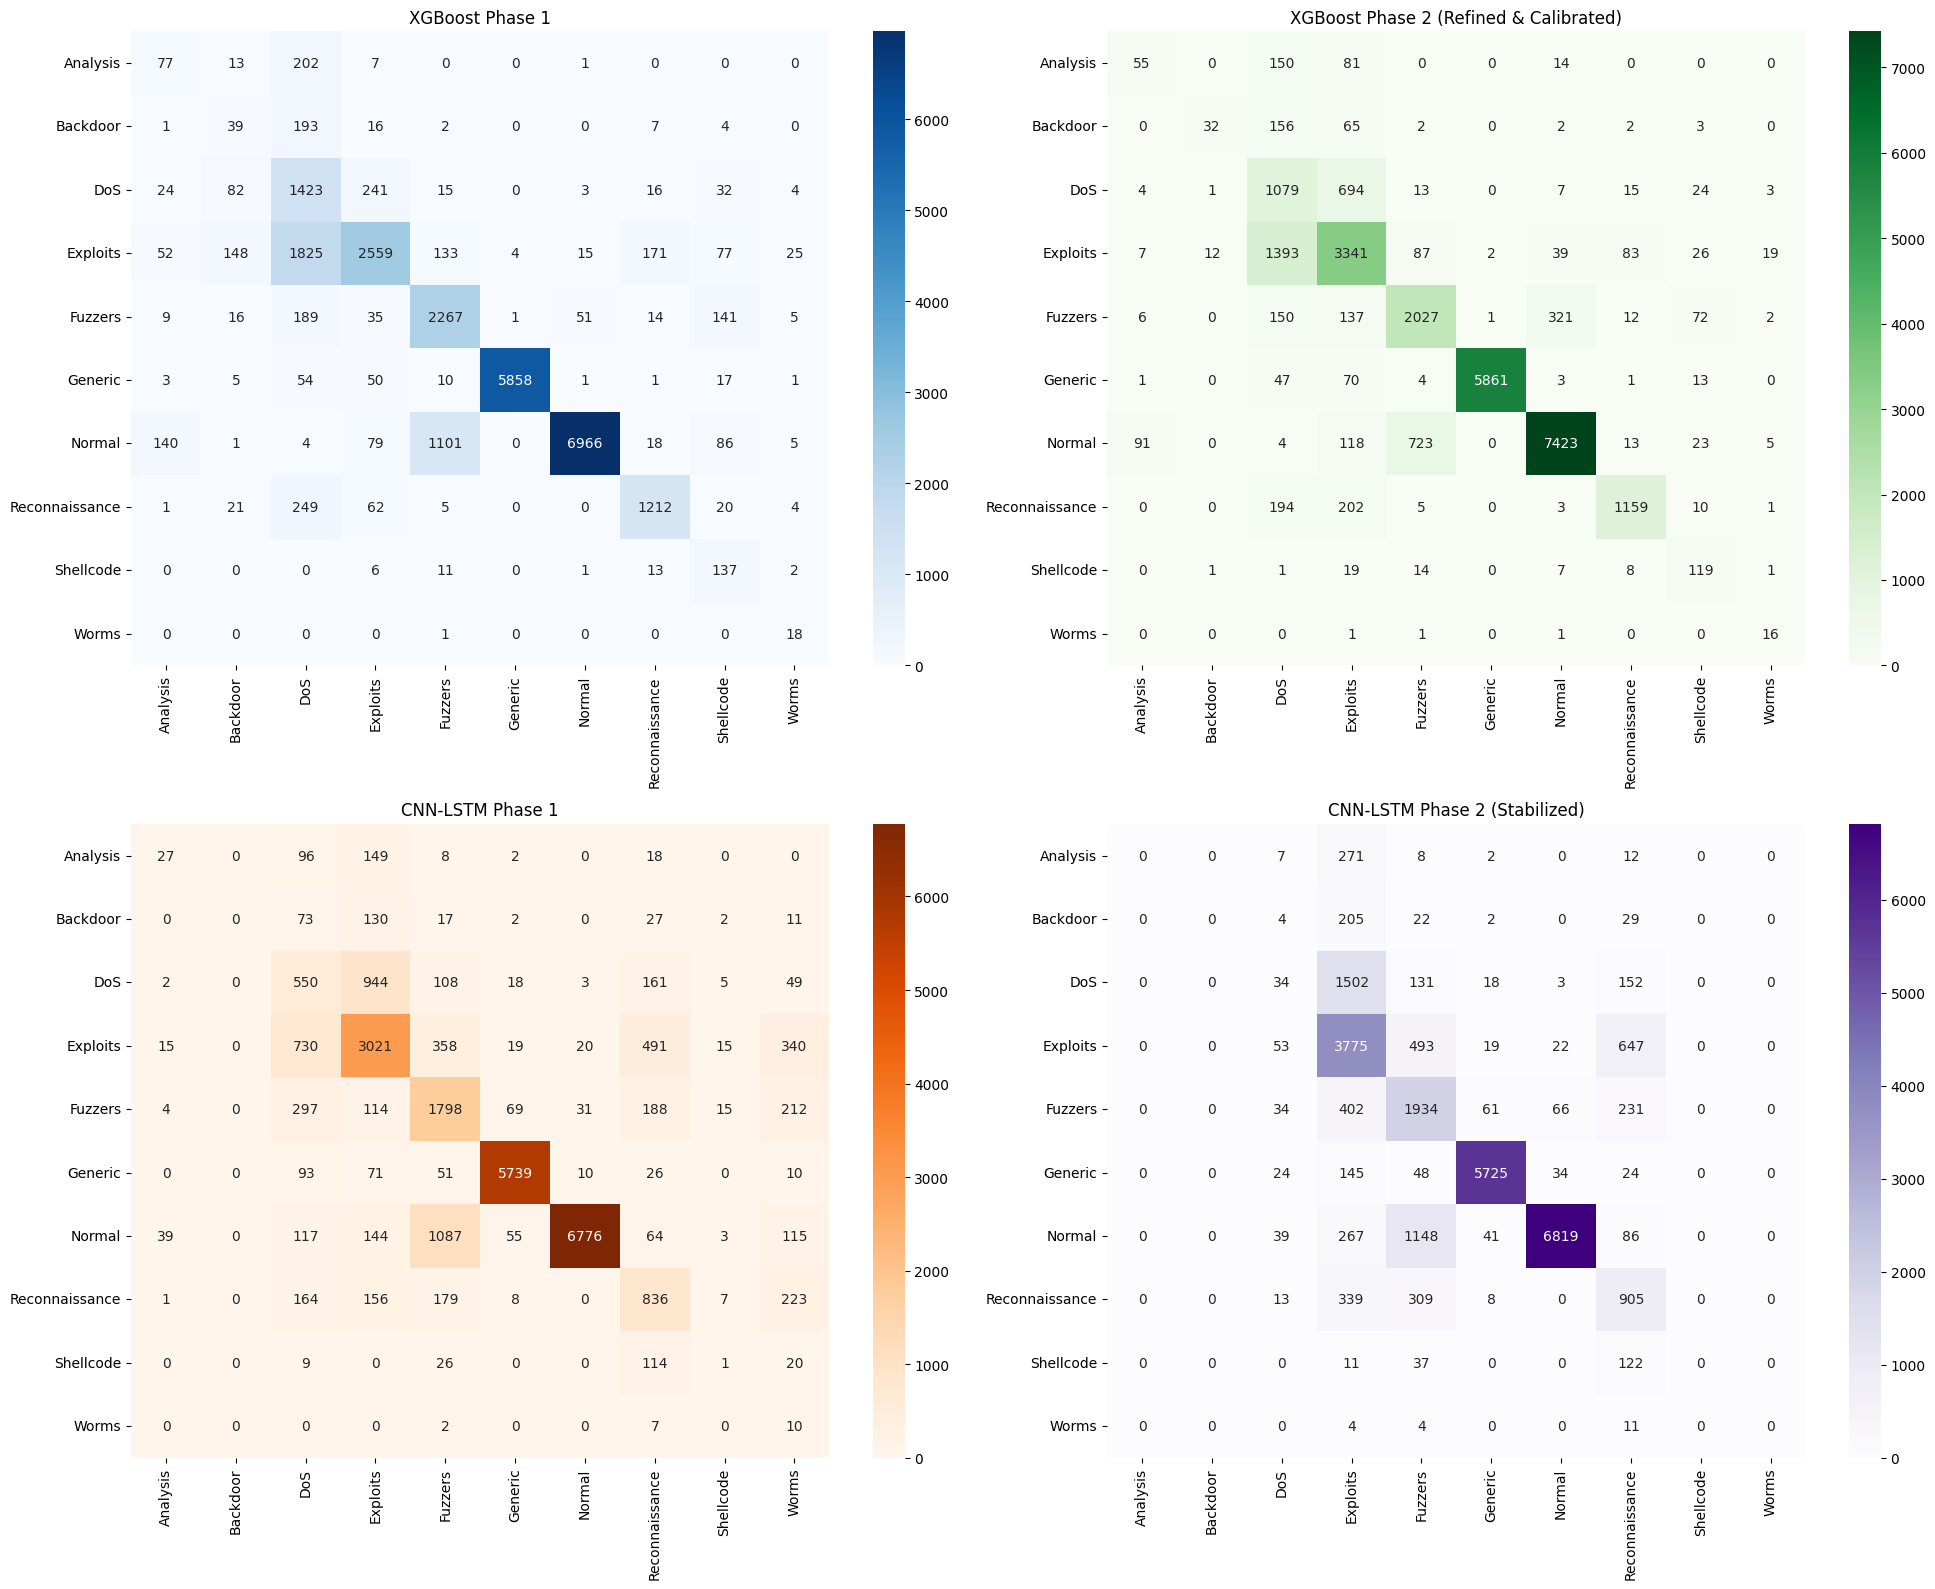

: 

In [ ]:
# Confusion Matrix Comparison (Phase 1 vs Phase 2)
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# XGB Phase 1
sns.heatmap(confusion_matrix(y_test_enc, y_p_xgb1), annot=True, fmt='d', cmap='Blues', ax=axes[0,0], xticklabels=classes, yticklabels=classes)
axes[0,0].set_title('XGBoost Phase 1')

# XGB Phase 2
sns.heatmap(confusion_matrix(y_test_enc, y_p_xgb2), annot=True, fmt='d', cmap='Greens', ax=axes[0,1], xticklabels=classes, yticklabels=classes)
axes[0,1].set_title('XGBoost Phase 2 (Refined & Calibrated)')

# CNN Phase 1
sns.heatmap(confusion_matrix(y_test_enc, y_p_cnn1), annot=True, fmt='d', cmap='Oranges', ax=axes[1,0], xticklabels=classes, yticklabels=classes)
axes[1,0].set_title('CNN-LSTM Phase 1')

# CNN Phase 2
sns.heatmap(confusion_matrix(y_test_enc, y_p_cnn2), annot=True, fmt='d', cmap='Purples', ax=axes[1,1], xticklabels=classes, yticklabels=classes)
axes[1,1].set_title('CNN-LSTM Phase 2 (Stabilized)')

plt.tight_layout()
plt.show()
